In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

pareto = pd.read_excel("Pareto.xlsx")

In [6]:
pareto = pareto.sort_values(by = "Frequência (Ocorrências)", ascending = False).reset_index(drop=True)
pareto["Acumulado"] = pareto["Frequência (Ocorrências)"].cumsum()
pareto["Percentual Acumulado"] = (pareto["Acumulado"]/pareto["Frequência (Ocorrências)"].sum())*100

In [7]:
pareto

,Categoria do Problema,Frequência (Ocorrências),Acumulado,Percentual Acumulado
0,Atraso na entrega,450,450,46.391753
1,Atendimento ao cliente ruim,240,690,71.134021
2,Defeito no produto,120,810,83.505155
3,Embalagem danificada,80,890,91.752577
4,Cobrança indevida,50,940,96.907216
5,Produto diferente do anunciado,30,970,100.000000


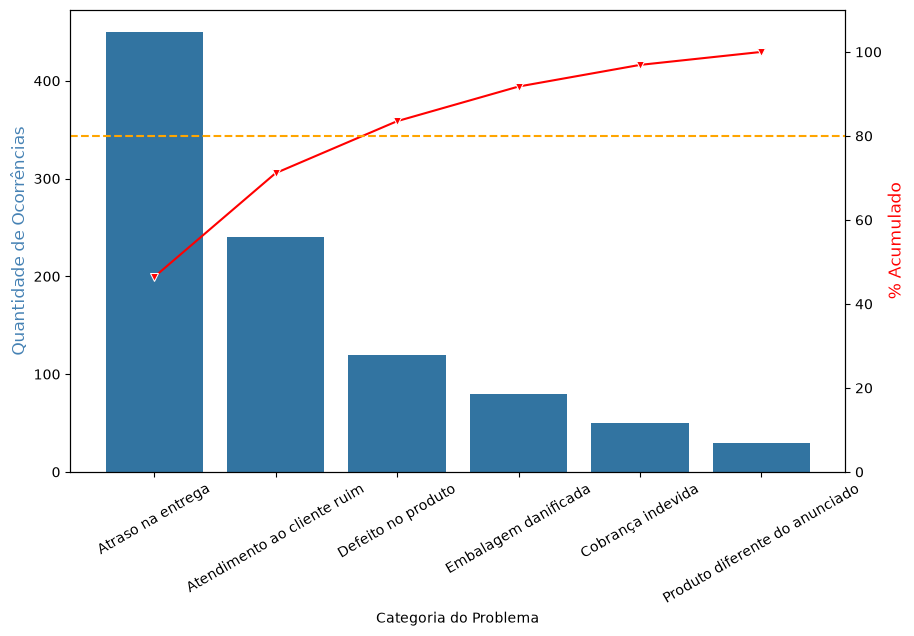

In [8]:
fig, ax1 = plt.subplots(figsize=(10,6))

sns.barplot(
    data = pareto,
    x = "Categoria do Problema",
    y = "Frequência (Ocorrências)",
    ax = ax1
)

ax1.set_ylabel("Quantidade de Ocorrências", color = "steelblue", fontsize = 12)
ax1.tick_params(axis = "x", rotation = 30)

ax2  = ax1.twinx()

sns.lineplot(
    data = pareto,
    x = pareto.index,
    y = "Percentual Acumulado",
    color = "red",
    marker = "v",
    ax = ax2
)

ax2.set_ylim(0,110)
ax2.set_ylabel("% Acumulado", color = "red", fontsize = 12)
ax2.axhline(80, color = "orange", linestyle = "--", label = "Corte 80%")

In [9]:
csv = pd.read_csv("avaliacao_servico_pareto.csv")

csv

,id_resposta,data_avaliacao,canal_atendimento,nota_satisfacao,causa_principal,comentario_adicional
0,1,2026-10-11,Chat Online,4,Tempo de espera elevado,Fiquei mais de 40 minutos na fila de espera an...
1,2,2026-10-26,Aplicativo,2,Atendimento pouco resolutivo,Fui transferido três vezes e ninguém resolveu ...
2,3,2026-10-24,E-mail,1,Tempo de espera elevado,NaN
3,4,2026-10-03,Aplicativo,1,Tempo de espera elevado,"O atendimento em si foi bom, mas a espera inic..."
4,5,2026-10-12,Telefone,5,Tempo de espera elevado,"Demora absurda no atendimento, quase desisti."
...,...,...,...,...,...,...
345,346,2026-10-10,Presencial,3,Tempo de espera elevado,Fila de espera interminável no horário de pico.
346,347,2026-10-28,Telefone,2,Tempo de espera elevado,Esperei muito tempo pelo retorno da equipe.
347,348,2026-10-18,Telefone,5,Atendimento pouco resolutivo,NaN
348,349,2026-10-25,Presencial,2,Falta de clareza nas informações,Os prazos informados no site são diferentes do...


In [18]:
csv = csv.groupby("causa_principal")["causa_principal"].size().reset_index(name = "Quantidade")

In [19]:
csv = csv.sort_values(by = "Quantidade", ascending = False).reset_index(drop=True)
csv["Acumulado"] = csv["Quantidade"].cumsum()
csv["Percentual Acumulado"] = (csv["Acumulado"]/csv["Quantidade"].sum())*100

In [20]:
csv

,causa_principal,Quantidade,Acumulado,Percentual Acumulado
0,Tempo de espera elevado,162,162,46.285714
1,Falha ou instabilidade no sistema/aplicativo,94,256,73.142857
2,Atendimento pouco resolutivo,42,298,85.142857
3,Cobrança ou fatura incorreta,21,319,91.142857
4,Falta de clareza nas informações,14,333,95.142857
5,Dificuldade de contato com o suporte,12,345,98.571429
6,Outros,5,350,100.000000


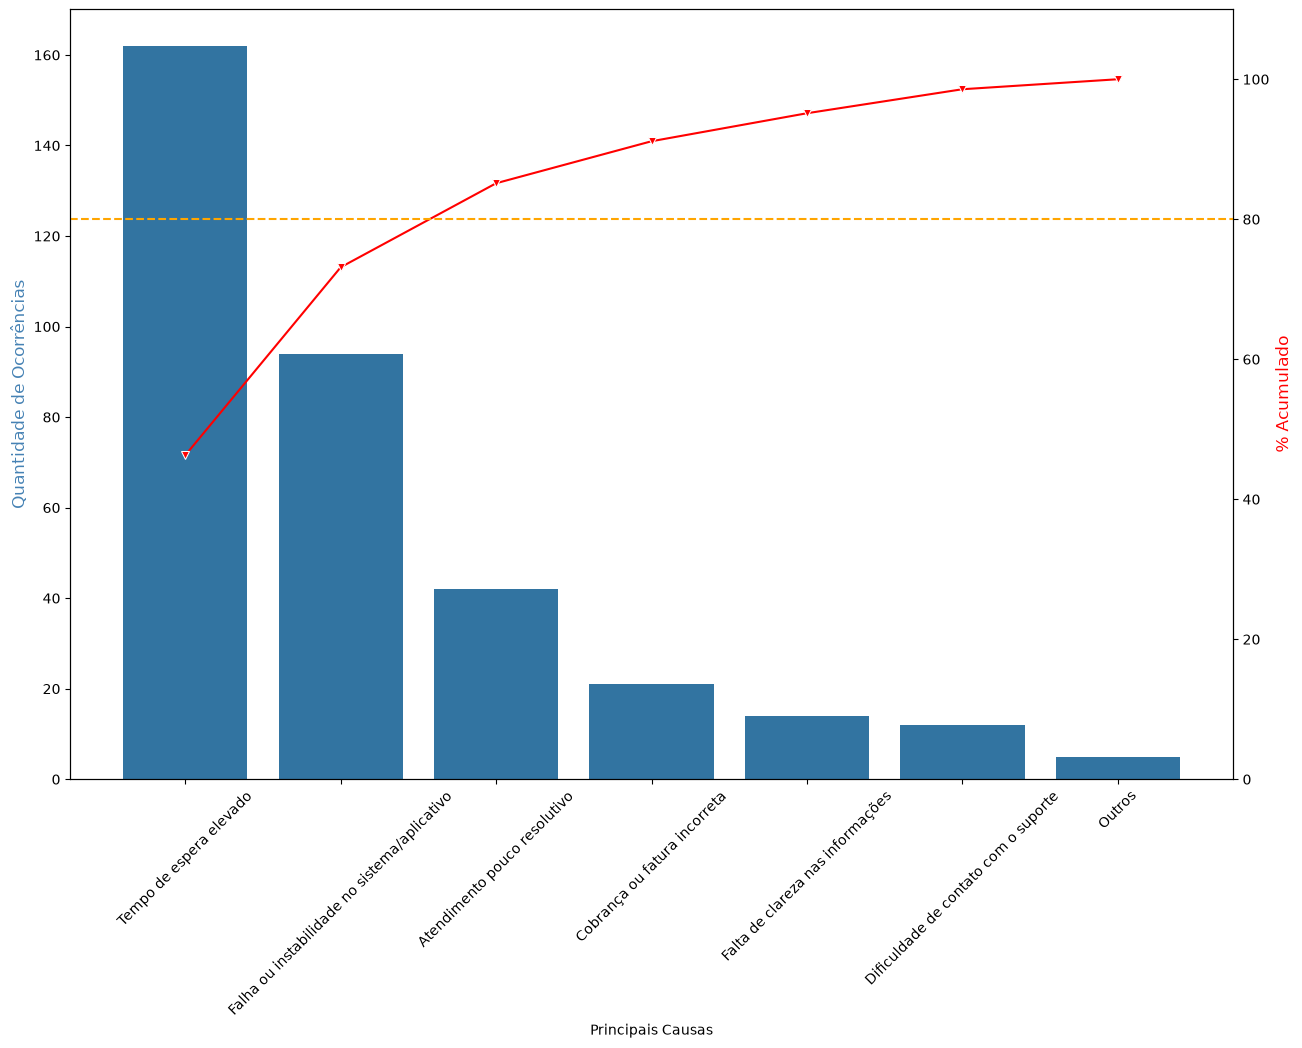

In [26]:
fig, ax1 = plt.subplots(figsize=(15,10))

sns.barplot(
    data = csv,
    x = "causa_principal",
    y = "Quantidade",
    ax = ax1
)
ax1.set_xlabel("Principais Causas")
ax1.set_ylabel("Quantidade de Ocorrências", color = "steelblue", fontsize = 12)
ax1.tick_params(axis = "x", rotation = 45)

ax2  = ax1.twinx()

sns.lineplot(
    data = csv,
    x = csv.index,
    y = "Percentual Acumulado",
    color = "red",
    marker = "v",
    ax = ax2
)

ax2.set_ylim(0,110)
ax2.set_ylabel("% Acumulado", color = "red", fontsize = 12)
ax2.axhline(80, color = "orange", linestyle = "--", label = "Corte 80%")